# 03 · Đánh giá mô hình

Chỉ dùng **tập test** (người nói chưa từng xuất hiện khi huấn luyện / chọn tham số) cho số liệu cuối cùng.
1. Phân loại 4 lớp: accuracy (kèm khoảng tin cậy), báo cáo theo lớp, ma trận nhầm lẫn.
2. Đọc log-likelihood đúng cách.
3. Từ chối từ khác / nhiễu.
4. Độ bền theo SNR và âm lượng.
5. Bản thu riêng từ mic của bạn và độ trễ.

In [1]:
import os, sys, pathlib, warnings, time
p = pathlib.Path.cwd().resolve()
ROOT = next((c for c in [p, *p.parents] if (c / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook từ bên trong thư mục dự án (nơi có config.py).")
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import matplotlib.pyplot as plt
import joblib
from config import Config, TARGET_WORDS
from speech import dataset as ds
from speech.features import utterance_features
from speech.plots import setup_style
setup_style()

cfg = Config()
N_JOBS = min(4, os.cpu_count() or 1)
print("Thư mục dự án :", ROOT)
print("Dữ liệu gốc   :", cfg.data.data_root)

from sklearn.metrics import classification_report, confusion_matrix
from speech.hmm import load_bundle, filler_loglik
from speech.evaluate import score_matrix, wilson_interval, mix_at_snr, apply_gain_db, rms_dbfs
from speech.features import compute_features
from speech.plots import plot_confusion, plot_det
from speech.recognizer import SpeechRecognizer

WEIGHTS = pathlib.Path(cfg.data.weights_dir) / "hmm_gmm_speech_models.pkl"
b = load_bundle(WEIGHTS)
models, filler, thr = b["models"], b["filler"], b["thresholds"]
saved_data_cfg = cfg.data
cfg = b["config"]; cfg.data = saved_data_cfg          # tiền xử lý lấy đúng từ lúc huấn luyện
sr = cfg.audio.sample_rate
print("Ngưỡng từ chối:", thr)

Thư mục dự án : D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj
Dữ liệu gốc   : D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj\data\speech_commands_v0.02
Ngưỡng từ chối: {'min_llr_per_frame': -0.5520075469669431, 'temperature': 19.952623149688797}


In [2]:
# Tải dữ liệu (~2.3 GB) nếu chưa có. Trên Colab nên để dữ liệu ở đĩa cục bộ (/content), không để trên Drive.
if not (pathlib.Path(cfg.data.data_root) / "testing_list.txt").exists():
    ds.download_speech_commands(cfg.data.data_root, cfg.data.url)

Nạp cache đặc trưng: D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj\cache\features_b8aed20c08_150_600.joblib
Số mẫu test: 1632
Accuracy = 0.9749   (khoảng tin cậy 95% Wilson: 0.9661 – 0.9814)
              precision    recall  f1-score   support

          up      0.954     0.988     0.971       421
        down      0.992     0.968     0.980       405
        left      0.960     0.985     0.972       411
       right      0.997     0.957     0.977       395

    accuracy                          0.975      1632
   macro avg      0.976     0.975     0.975      1632
weighted avg      0.975     0.975     0.975      1632



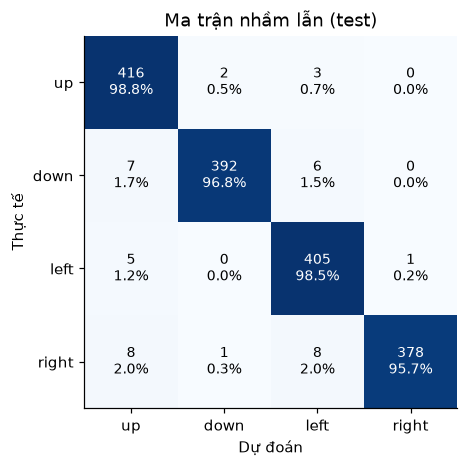

In [3]:
data = ds.build_feature_sets(cfg, n_jobs=N_JOBS)
seqs, y_idx = [], []
for i, w in enumerate(TARGET_WORDS):
    for f in data["sets"]["test"][w]:
        seqs.append(np.asarray(f, np.float64)); y_idx.append(i)
y_idx = np.array(y_idx)
S = score_matrix(models, seqs)
T_len = np.array([len(s) for s in seqs])
pred = S.argmax(1)
k, n = int((pred == y_idx).sum()), len(y_idx)
lo, hi = wilson_interval(k, n)
print(f"Số mẫu test: {n}\nAccuracy = {k/n:.4f}   (khoảng tin cậy 95% Wilson: {lo:.4f} – {hi:.4f})")
print(classification_report(y_idx, pred, target_names=TARGET_WORDS, digits=3))
plot_confusion(confusion_matrix(y_idx, pred), TARGET_WORDS, "Ma trận nhầm lẫn (test)"); plt.show()

## 2. Đọc log-likelihood đúng cách

Tổng log-likelihood của một câu là tổng trên ~50 khung × 39 chiều, nên là số âm rất lớn và dao động mạnh giữa các câu **cho cả 4 mô hình cùng lúc**.
Vì vậy phải so sánh **bốn mô hình trên cùng một câu**: `gap = LL(đúng) − LL(sai tốt nhất)`. Chênh 10 đơn vị log tương đương tỷ lệ khả năng e¹⁰ ≈ 22,000 lần.

Độ lệch chuẩn LL giữa các câu (một mô hình): 893 | giữa các mô hình trên cùng câu: 153
Tương quan LL giữa các cặp mô hình: 0.961
gap: trung vị 203, phân vị 5% = 43; trung bình mỗi khung: 3.68 nat/khung


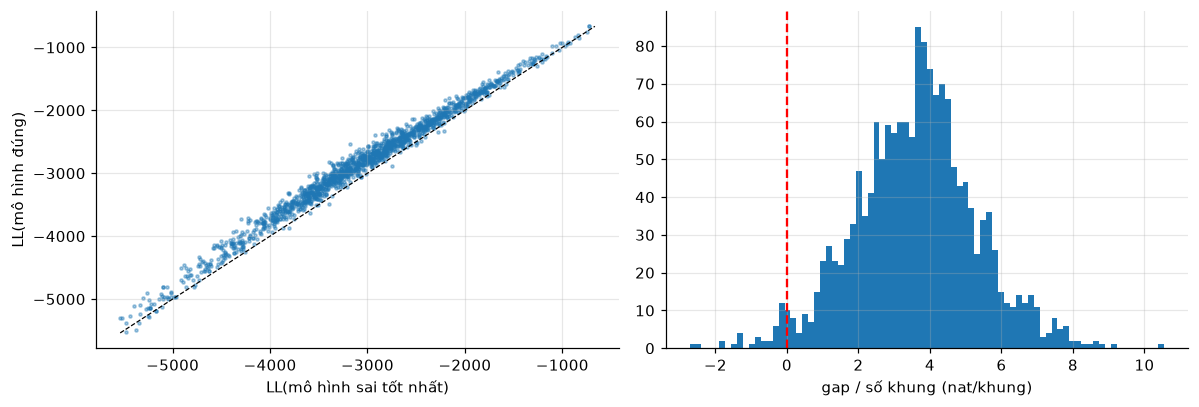

In [4]:
ar = np.arange(len(S))
ll_true = S[ar, y_idx]
S_w = S.copy(); S_w[ar, y_idx] = -np.inf
gap = ll_true - S_w.max(axis=1)
off = np.corrcoef(S.T)[np.triu_indices(S.shape[1], 1)]
print(f"Độ lệch chuẩn LL giữa các câu (một mô hình): {S[:, 0].std():.0f} | giữa các mô hình trên cùng câu: {(S - S.mean(axis=1, keepdims=True)).std():.0f}")
print(f"Tương quan LL giữa các cặp mô hình: {off.mean():.3f}")
print(f"gap: trung vị {np.median(gap):.0f}, phân vị 5% = {np.percentile(gap, 5):.0f}; trung bình mỗi khung: {np.median(gap / T_len):.2f} nat/khung")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(S_w.max(axis=1), ll_true, s=4, alpha=0.4)
lim = [min(S_w.max(axis=1).min(), ll_true.min()), max(S_w.max(axis=1).max(), ll_true.max())]
ax[0].plot(lim, lim, "k--", lw=0.8); ax[0].set_xlabel("LL(mô hình sai tốt nhất)"); ax[0].set_ylabel("LL(mô hình đúng)")
ax[1].hist(gap / T_len, bins=80); ax[1].axvline(0, color="r", ls="--"); ax[1].set_xlabel("gap / số khung (nat/khung)")
plt.tight_layout(); plt.show()

## 3. Từ chối từ khác và nhiễu

Cần từ chối: (a) **từ khác** trong 31 từ còn lại của dataset (tập test), (b) **nhiễu nền** (phần 30% cuối của mỗi file nhiễu, tách khỏi phần huấn luyện filler).
Trong ứng dụng thật, nhiễu thuần phần lớn đã bị bộ endpoint loại trước khi tới HMM.

Ngưỡng LLR/khung = -0.552
  chấp nhận từ đúng (4 từ, test) : 96.3%
  nhận nhầm 'từ khác' (n=1138)   : 47.6%
  nhận nhầm 'nhiễu nền' (n=300)  : 0.0%


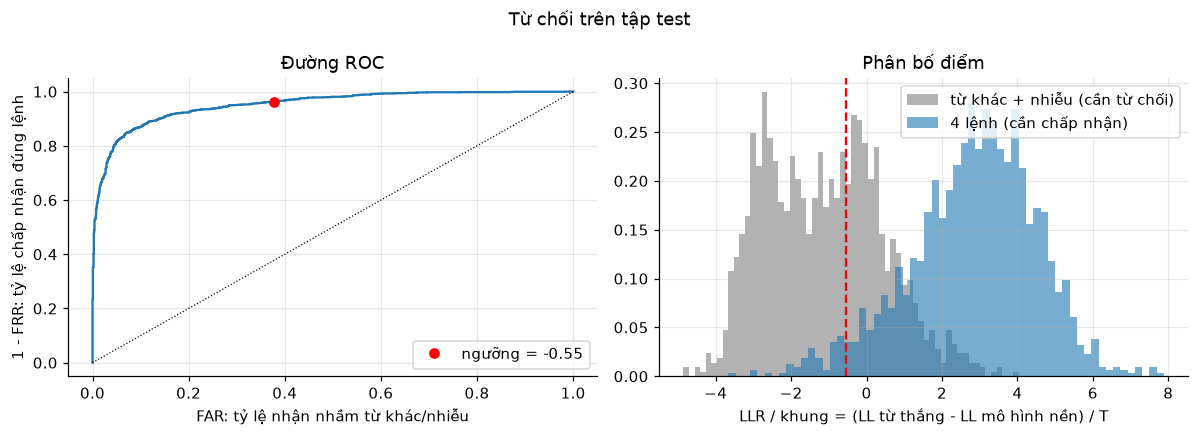

In [5]:
rng = np.random.default_rng(123)
bank = ds.load_noise_bank(cfg.data.data_root, sr)
noise_clips = ds.sample_noise_clips(bank, "eval", 300, 0.6, sr, rng)
noi = [f for f in (compute_features(c, sr, cfg.features) for c in noise_clips) if f is not None]
unk = [np.asarray(x, np.float64) for x in data["unknown"]["test"]]

def llr(S_, seqs_):
    return (S_.max(axis=1) - filler_loglik(filler, seqs_)) / np.array([len(s) for s in seqs_])

pos_llr = llr(S, seqs)
unk_llr, noi_llr = llr(score_matrix(models, unk), unk), llr(score_matrix(models, noi), noi)
t = thr["min_llr_per_frame"]
print(f"Ngưỡng LLR/khung = {t:.3f}")
print(f"  chấp nhận từ đúng (4 từ, test) : {np.mean(pos_llr >= t):.1%}")
print(f"  nhận nhầm 'từ khác' (n={len(unk_llr)})   : {np.mean(unk_llr >= t):.1%}")
print(f"  nhận nhầm 'nhiễu nền' (n={len(noi_llr)})  : {np.mean(noi_llr >= t):.1%}")
plot_det(pos_llr, np.concatenate([unk_llr, noi_llr]), t, "Từ chối trên tập test"); plt.show()

## 4. Độ bền: nhiễu và âm lượng

Trộn nhiễu nền (phần 30% cuối của file nhiễu) ở các mức SNR và giảm âm lượng. Clip bị endpoint coi là không có tiếng nói được tính là **sai**.

SNR    sạch: accuracy 0.970 | bị endpoint loại 0.5%
SNR   20 dB: accuracy 0.966 | bị endpoint loại 0.5%
SNR   10 dB: accuracy 0.945 | bị endpoint loại 0.8%
SNR    5 dB: accuracy 0.897 | bị endpoint loại 1.4%
SNR    0 dB: accuracy 0.620 | bị endpoint loại 26.0%
Gain    0 dB : accuracy 0.970 | bị endpoint loại 0.5%
Gain  -10 dB : accuracy 0.970 | bị endpoint loại 0.5%
Gain  -20 dB : accuracy 0.970 | bị endpoint loại 0.5%
Gain  -30 dB : accuracy 0.970 | bị endpoint loại 0.5%


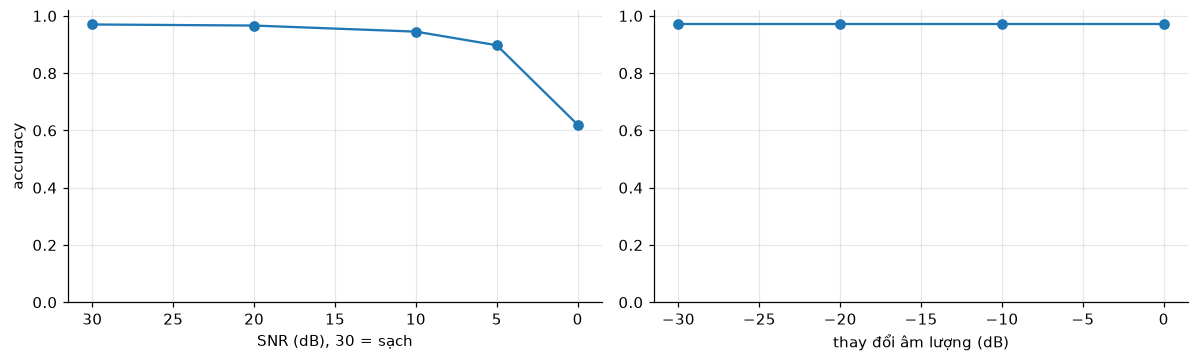

In [6]:
test_items = [i for i in ds.get_items(cfg, TARGET_WORDS) if i["split"] == "test"]
test_items = [test_items[j] for j in np.random.default_rng(7).permutation(len(test_items))[:800]]
noise_pool = ds.sample_noise_clips(bank, "eval", len(test_items), 1.0, sr, np.random.default_rng(11))
names = list(models)

def run_condition(transform):
    correct = rejected = 0
    for it, nz in zip(test_items, noise_pool):
        y = ds.read_wav(it["path"], sr)
        f = utterance_features(transform(y, np.pad(nz, (0, max(0, len(y) - len(nz))))[:len(y)]), cfg)
        if f is None:
            rejected += 1; continue
        correct += names[int(np.argmax([m.score(f) for m in models.values()]))] == it["word"]
    return correct / len(test_items), rejected / len(test_items)

snrs, gains = [None, 20, 10, 5, 0], [0, -10, -20, -30]
res_snr = [run_condition(lambda y, nz, s=s: y if s is None else mix_at_snr(y, nz, s)) for s in snrs]
res_gain = [run_condition(lambda y, nz, g=g: apply_gain_db(y, g)) for g in gains]
for s, (a, r) in zip(snrs, res_snr):
    print(f"SNR {'sạch' if s is None else str(s) + ' dB':>7}: accuracy {a:.3f} | bị endpoint loại {r:.1%}")
for g, (a, r) in zip(gains, res_gain):
    print(f"Gain {g:>4} dB : accuracy {a:.3f} | bị endpoint loại {r:.1%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot([30 if s is None else s for s in snrs], [a for a, _ in res_snr], "o-"); ax[0].invert_xaxis()
ax[0].set_xlabel("SNR (dB), 30 = sạch"); ax[0].set_ylabel("accuracy"); ax[0].set_ylim(0, 1.02)
ax[1].plot(gains, [a for a, _ in res_gain], "o-"); ax[1].set_xlabel("thay đổi âm lượng (dB)"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

## 5. Bản thu riêng từ mic của bạn và độ trễ

Chạy `python tools/record_samples.py --n 15` trước. Dùng đúng pipeline của ứng dụng (`SpeechRecognizer`), nên các con số phản ánh những gì demo sẽ làm.

Bản thu riêng: 180 clip | accuracy (từ thắng) = 0.967 (6 lỗi)
  từ đúng được CHO QUA bởi bộ từ chối : 99.4%   <- thấp nghĩa là giao diện không hiện từ
  LLR/khung của từ đúng (phân vị 5/50/95): [0.88 2.33 3.71] | ngưỡng = -0.55


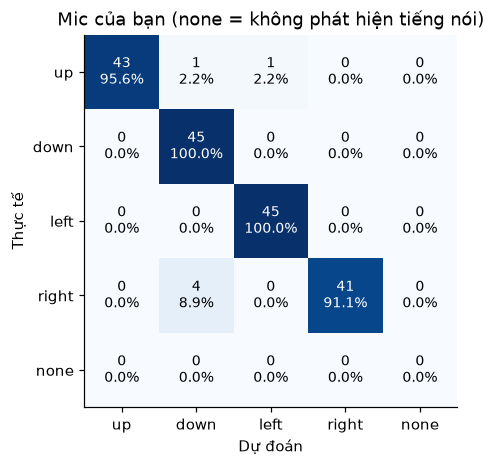

  lỗi: right -> down ok LLR 0.84 -39.0 dBFS
  lỗi: right -> down ok LLR 1.41 -39.3 dBFS
  lỗi: right -> down ok LLR 1.37 -39.6 dBFS
  lỗi: right -> down ok LLR 1.31 -39.5 dBFS
  lỗi: up -> left ok LLR 0.15 -40.2 dBFS
  lỗi: up -> down ok LLR 1.84 -31.8 dBFS
Độ trễ trung bình mỗi lần nhận dạng: 7.6 ms


In [7]:
MY_DIR = ROOT / "data" / "my_recordings"
files = sorted(MY_DIR.glob("*/*.wav")) if MY_DIR.exists() else []
rec = SpeechRecognizer(str(WEIGHTS))
if not files:
    print("Chưa có bản thu riêng. Chạy: python tools/record_samples.py")
else:
    yt, yp, acc_flag, rows = [], [], [], []
    for f in files:
        y = ds.read_wav(str(f), sr)
        p = rec.predict(y)
        yt.append(f.parent.name); yp.append(p.word or "none"); acc_flag.append(p.accepted)
        rows.append((f.parent.name, p.word, p.reason, p.llr, rms_dbfs(y)))
    yt, yp, acc_flag = np.array(yt), np.array(yp), np.array(acc_flag)
    ok = yt == yp
    print(f"Bản thu riêng: {len(files)} clip | accuracy (từ thắng) = {ok.mean():.3f} ({int((~ok).sum())} lỗi)")
    print(f"  từ đúng được CHO QUA bởi bộ từ chối : {acc_flag[ok].mean():.1%}   <- thấp nghĩa là giao diện không hiện từ")
    llr_ok = np.array([r[3] for r, o in zip(rows, ok) if o and np.isfinite(r[3])])
    print(f"  LLR/khung của từ đúng (phân vị 5/50/95): {np.round(np.percentile(llr_ok, [5, 50, 95]), 2)} | ngưỡng = {thr['min_llr_per_frame']:.2f}")
    labels_ext = TARGET_WORDS + ["none"]
    plot_confusion(confusion_matrix(yt, yp, labels=labels_ext), labels_ext, "Mic của bạn (none = không phát hiện tiếng nói)"); plt.show()
    for r in [r for r in rows if r[0] != r[1]][:10]:
        print("  lỗi:", r[0], "->", r[1], r[2], f"LLR {r[3]:.2f}", f"{r[4]:.1f} dBFS")
probe = [ds.read_wav(i["path"], sr) for i in test_items[:100]]
t0 = time.perf_counter()
for y in probe:
    rec.predict(y)
print(f"Độ trễ trung bình mỗi lần nhận dạng: {(time.perf_counter() - t0) / len(probe) * 1000:.1f} ms")